# Stroke risk - JarvisTEC (`stroke`)

**Team members:** Anthony Jafeth Arias Robleto (2020007243), Randy Espinoza Downing (2021031263), Kenneth Jhoan Araya Arguedas (2024177221)
**Dataset:** [Stroke Prediction Dataset (Kaggle, fedesoriano/stroke-prediction-dataset)](https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset), `healthcare-dataset-stroke-data.csv`.

| Section | Points |
|---|---|
| 1. Problem analysis | 0.5 |
| 2. Data understanding | 0.5 |
| 3. Data exploration | 0.5 |
| 4. Model | 2 |
| 5. Evaluation | 1 |
| 6. Conclusion | 0.5 |

## Configuration

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display

warnings.filterwarnings("ignore")

# ------------------------- EDIT THESE VALUES -------------------------
# Must match `name` in backend/models/<package>/adapter.py.
MODEL_NAME = "stroke"
# CSV path relative to training/<name>/ (data/ is git-ignored).
DATA_PATH = "../../data/stroke/healthcare-dataset-stroke-data.csv"
TARGET_COLUMN = "stroke"  # 1 = the patient had a stroke, 0 = not
TASK_TYPE = "classification"  # "classification" or "regression"
IS_TIME_SERIES = False  # True for bitcoin, avocado...: chronological split
DATE_COLUMN = None  # date column name when IS_TIME_SERIES is True
# Patient identifier: carries no clinical information.
EXCLUDED_COLUMNS = ["id"]
SEED = 42
# ---------------------------------------------------------------------

ARTIFACTS = Path("../../artifacts")
ARTIFACTS.mkdir(exist_ok=True)
np.random.seed(SEED)
assert TASK_TYPE in ("classification", "regression")

## 1. Problem analysis

The goal is to estimate the **probability that a person has had a stroke** from ten variables that are cheap to collect: age, gender, hypertension, heart disease, marital status, type of work, type of residence, average glucose level, body mass index and smoking status. Stroke is one of the leading causes of death and disability in the world (Feigin et al., 2021), and most of its burden is attributed to modifiable risk factors such as hypertension, smoking and diabetes (O'Donnell et al., 2016). A tool like this could help decide **who should be sent for a medical check-up first**. It is a screening aid: it produces an estimate, **never a diagnosis**.

- **Task type:** binary classification. The target `stroke` is 1 when the patient had a stroke and 0 otherwise. The model outputs a probability, which is then turned into a risk level (low, moderate, high) with thresholds.
- **Why accuracy is not used:** only about 5 % of the patients had a stroke. A model that always answers "no stroke" is right 95 % of the time and identifies no patient.
- **Success metrics:** **ROC-AUC** (area under the ROC curve: how well the model ranks patients, independent of any threshold) is the metric used to select and tune the model. **PR-AUC** (area under the precision-recall curve, computed as average precision) is reported next to it because it is more informative than ROC-AUC when the positive class is rare (Saito & Rehmsmeier, 2015). The two metrics do not order the candidates in the same way; section 4 states this openly and says what selecting by PR-AUC would have changed. Once a decision threshold is fixed, the **recall**, **precision** and **F1 of the stroke class** and the **confusion matrix** are reported. Recall matters most, on the assumption that missing a patient at risk costs more than an unnecessary check-up. The model is always compared with a baseline that predicts the prevalence for every patient.
- **Support:** Wolf et al. (1991) built the Framingham stroke risk profile, a probability of stroke computed from age, blood pressure, diabetes, smoking and heart disease, which are inputs of the same kind as those used here.

## 2. Data understanding

In [2]:
df = pd.read_csv(DATA_PATH)
print("Rows, columns:", df.shape)
display(df.head())

Rows, columns: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [3]:
# snake_case names: the same fields the API receives
# (backend/models/stroke/schema.py). `Residence_type` -> `residence_type`.
df.columns = [c.strip().lower() for c in df.columns]

# "N/A" in `bmi` was read as a missing value by pandas.
print("Missing bmi:", df["bmi"].isna().sum())
print("Duplicated ids:", df["id"].duplicated().sum())
print(
    "Duplicated rows ignoring id:",
    df.drop(columns="id").duplicated().sum(),
)
display(df["gender"].value_counts())

# A single patient has gender "Other": one row cannot be learned from and
# would create a category the model has seen once. It is removed.
df = df[df["gender"] != "Other"].reset_index(drop=True)
print("Rows after removing it:", len(df))

Missing bmi: 201
Duplicated ids: 0
Duplicated rows ignoring id: 0


gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

Rows after removing it: 5109


In [4]:
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "% missing": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(),
})
display(summary)
print("Duplicated rows:", df.duplicated().sum())
display(df.describe(include="all").T)

,dtype,missing,% missing,unique
id,int64,0,0.00,5109
gender,str,0,0.00,2
age,float64,0,0.00,104
hypertension,int64,0,0.00,2
heart_disease,int64,0,0.00,2
ever_married,str,0,0.00,2
work_type,str,0,0.00,5
residence_type,str,0,0.00,2
avg_glucose_level,float64,0,0.00,3978
bmi,float64,201,3.93,418


Duplicated rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,5109.0,NaN,NaN,NaN,36513.985516,21162.008804,67.0,17740.0,36922.0,54643.0,72940.0
gender,5109,2,Female,2994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,5109.0,NaN,NaN,NaN,43.229986,22.613575,0.08,25.0,45.0,61.0,82.0
hypertension,5109.0,NaN,NaN,NaN,0.097475,0.296633,0.0,0.0,0.0,0.0,1.0
heart_disease,5109.0,NaN,NaN,NaN,0.054022,0.226084,0.0,0.0,0.0,0.0,1.0
ever_married,5109,2,Yes,3353,NaN,NaN,NaN,NaN,NaN,NaN,NaN
work_type,5109,5,Private,2924,NaN,NaN,NaN,NaN,NaN,NaN,NaN
residence_type,5109,2,Urban,2596,NaN,NaN,NaN,NaN,NaN,NaN,NaN
avg_glucose_level,5109.0,NaN,NaN,NaN,106.140399,45.285004,55.12,77.24,91.88,114.09,271.74
bmi,4908.0,NaN,NaN,NaN,28.89456,7.85432,10.3,23.5,28.1,33.1,97.6


**Data description.** Each row is one patient. The file has **5110 patients** and 12 columns. The Kaggle page does not name the hospital or country the records come from (it lists the source as confidential), so the population it represents is unknown.

| Variable | Meaning | Type / unit |
|---|---|---|
| `id` | patient identifier | integer, unique |
| `gender` | gender | categorical: `Female`, `Male` (and one `Other`) |
| `age` | age | years, 0.08-82 (babies are recorded as fractions of a year) |
| `hypertension` | has hypertension | 0 / 1 |
| `heart_disease` | has a heart disease | 0 / 1 |
| `ever_married` | has ever been married | `Yes`, `No` |
| `work_type` | type of work | `Private`, `Self-employed`, `Govt_job`, `children`, `Never_worked` |
| `residence_type` | where the patient lives | `Urban`, `Rural` |
| `avg_glucose_level` | average blood glucose level | 55-272; the source does not state the unit (the range is consistent with mg/dL) |
| `bmi` | body mass index | kg/m2, 10.3-97.6 |
| `smoking_status` | smoking status | `never smoked`, `formerly smoked`, `smokes`, `Unknown` |
| `stroke` | the patient had a stroke (**target**) | 0 / 1 |

**Data quality:**
- **Missing values:** `bmi` has **201 missing values** (3.93 %), written as `N/A` in the file. They are imputed with the median inside the `Pipeline`, so that no patient is dropped and the backend tolerates a missing BMI.
- **Hidden missing values:** `smoking_status` is `Unknown` for 1544 patients (30 %). It is kept as its own category instead of being imputed.
- **Duplicates:** none (no repeated `id` and no repeated row when `id` is ignored).
- **`id` is excluded:** it identifies the patient and carries no clinical information.
- **One patient with gender `Other`:** removed, because a category with a single example cannot be learned. **5109 patients** remain.
- **Extreme values:** 13 patients have a BMI above 60 (maximum 97.6) and 120 are younger than 2 years. They are kept because they are few and may be real.
- **Children and teenagers are kept.** The data is not restricted to adults: ages go from 0.08 to 82, 856 of the 5109 patients are under 18 and 687 have `work_type = children` (section 3). Strokes are almost absent there: the `children` group has 2 strokes (0.29 %), and only 8 of the 249 strokes are in the 2169 patients under 40. Screening for stroke risk is a question about adults, so these patients are easy negatives: almost any model gives them a low probability, which **inflates accuracy and specificity** (and helps the ranking metrics) without showing that the model separates the adults who are really at risk. No adult-only model was trained, so the size of this effect was not measured; the results by age band in section 5 show where the model actually works.
- **The dataset does not say when the stroke happened** relative to the other measurements, so the data describes an association ("patients like this one had a stroke"), not a forecast with a time horizon.

## 3. Data exploration

stroke
0    95.13
1     4.87
Name: % of each class, dtype: float64

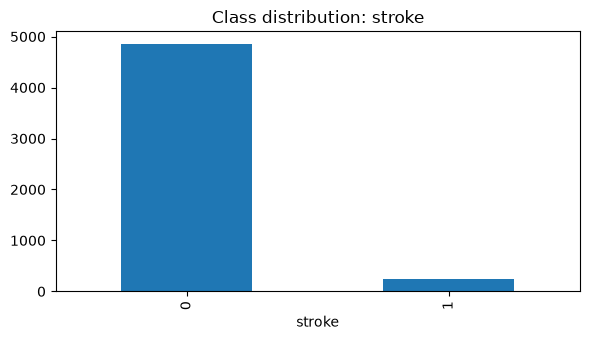

In [5]:
target = TARGET_COLUMN
fig, ax = plt.subplots(figsize=(6, 3.5))
if TASK_TYPE == "classification":
    df[target].value_counts().sort_index().plot(kind="bar", ax=ax)
    ax.set_title(f"Class distribution: {target}")
    shares = (df[target].value_counts(normalize=True) * 100).round(2)
    display(shares.rename("% of each class"))
else:
    df[target].plot(kind="hist", bins=40, ax=ax)
    ax.set_title(f"Distribution of {target}")
plt.tight_layout()
plt.show()

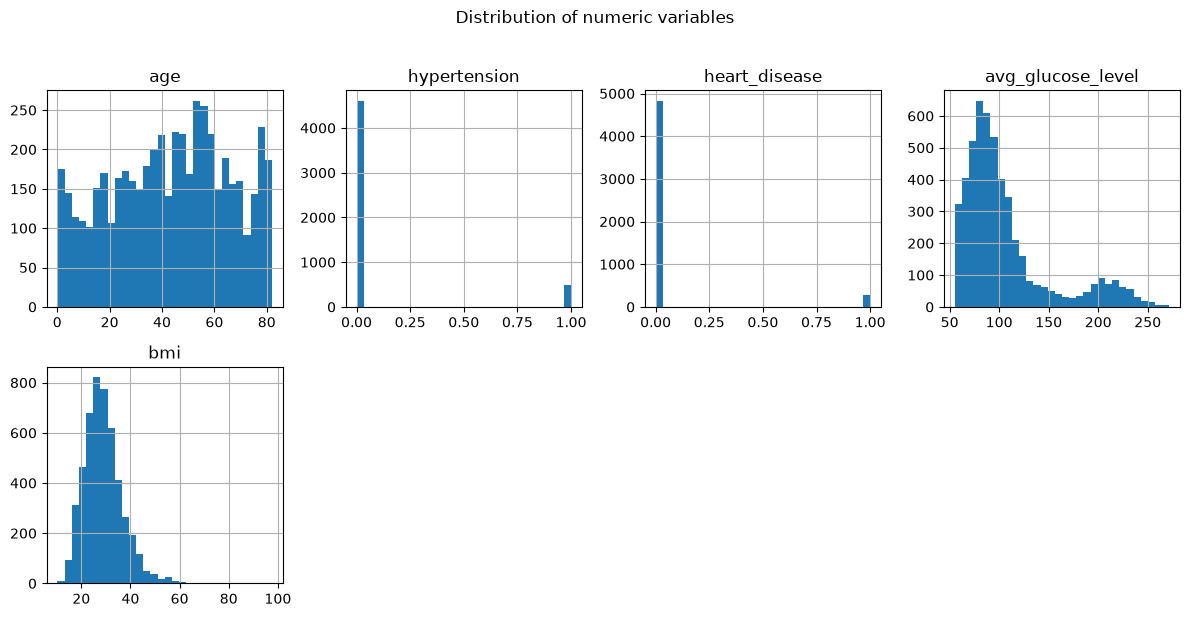

In [6]:
numeric_columns = [
    c for c in df.select_dtypes("number").columns
    if c not in EXCLUDED_COLUMNS + [target]
]
rows = (len(numeric_columns) + 3) // 4
df[numeric_columns].hist(bins=30, figsize=(12, 3 * rows), layout=(-1, 4))
plt.suptitle("Distribution of numeric variables", y=1.02)
plt.tight_layout()
plt.show()

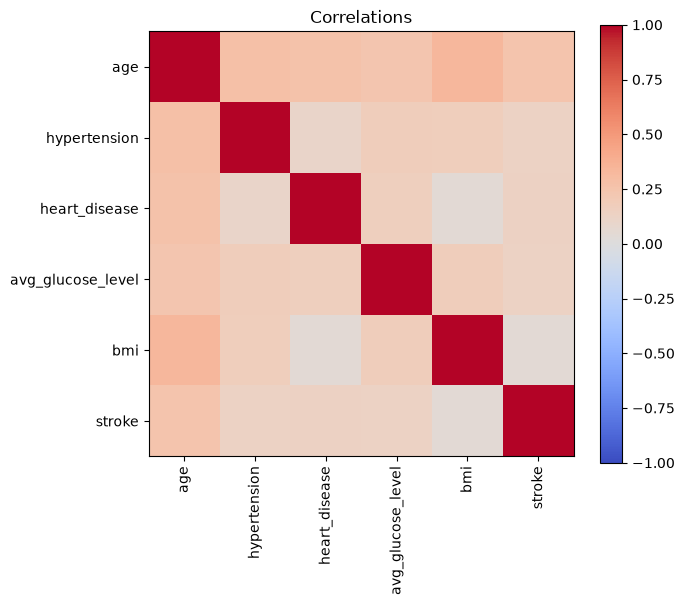

age                  0.245239
heart_disease        0.134905
avg_glucose_level    0.131991
hypertension         0.127891
bmi                  0.042341
Name: correlation with the target, dtype: float64

In [7]:
if len(numeric_columns) > 1:
    corr = df[numeric_columns + [target]].select_dtypes("number").corr()
    fig, ax = plt.subplots(figsize=(7, 6))
    image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)))
    ax.set_xticklabels(corr.columns, rotation=90)
    ax.set_yticks(range(len(corr)))
    ax.set_yticklabels(corr.columns)
    plt.colorbar(image)
    ax.set_title("Correlations")
    plt.tight_layout()
    plt.show()
    if pd.api.types.is_numeric_dtype(df[target]):
        display(
            corr[target].drop(target)
            .sort_values(key=abs, ascending=False)
            .rename("correlation with the target")
        )

In [8]:
categorical_columns = [
    c for c in df.select_dtypes(exclude="number").columns
    if c not in EXCLUDED_COLUMNS + [target, DATE_COLUMN]
]
for column in categorical_columns[:6]:
    print(f"\n{column}: {df[column].nunique()} categories")
    display(df[column].value_counts().head(10))


gender: 2 categories


gender
Female    2994
Male      2115
Name: count, dtype: int64


ever_married: 2 categories


ever_married
Yes    3353
No     1756
Name: count, dtype: int64


work_type: 5 categories


work_type
Private          2924
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64


residence_type: 2 categories


residence_type
Urban    2596
Rural    2513
Name: count, dtype: int64


smoking_status: 4 categories


smoking_status
never smoked       1892
Unknown            1544
formerly smoked     884
smokes              789
Name: count, dtype: int64

,patients,strokes,stroke rate (%)
age,,,
< 40,2169,8,0.37
40-49,730,12,1.64
50-59,834,48,5.76
60-69,621,47,7.57
70+,755,134,17.75


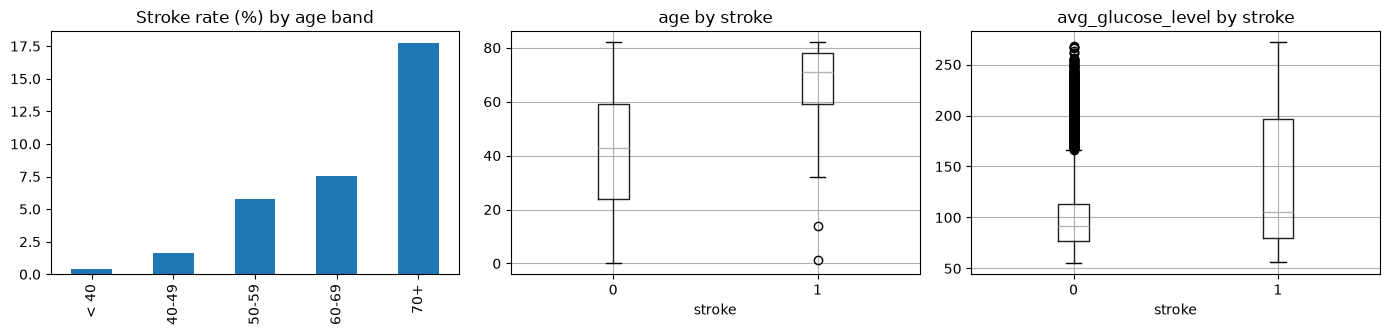

,patients,strokes,stroke rate (%)
hypertension,,,
0,4611,183,3.97
1,498,66,13.25


,patients,strokes,stroke rate (%)
heart_disease,,,
0,4833,202,4.18
1,276,47,17.03


,patients,strokes,stroke rate (%)
gender,,,
Female,2994,141,4.71
Male,2115,108,5.11


,patients,strokes,stroke rate (%)
ever_married,,,
No,1756,29,1.65
Yes,3353,220,6.56


,patients,strokes,stroke rate (%)
work_type,,,
Govt_job,657,33,5.02
Never_worked,22,0,0.00
Private,2924,149,5.10
Self-employed,819,65,7.94
children,687,2,0.29


,patients,strokes,stroke rate (%)
residence_type,,,
Rural,2513,114,4.54
Urban,2596,135,5.20


,patients,strokes,stroke rate (%)
smoking_status,,,
Unknown,1544,47,3.04
formerly smoked,884,70,7.92
never smoked,1892,90,4.76
smokes,789,42,5.32


,age,avg_glucose_level,bmi
stroke (median values),,,
0,43.0,91.5,28.0
1,71.0,105.2,29.7


Youngest patients with a stroke:
[1.32, 14.0, 32.0, 38.0, 38.0]
Strokes under 40: 8


In [9]:
# Stroke rate (%) by age band and by each category.
AGE_BINS = [0, 40, 50, 60, 70, 120]
AGE_LABELS = ["< 40", "40-49", "50-59", "60-69", "70+"]


def stroke_rate(group):
    table = df.groupby(group, observed=True)[target].agg(
        patients="size", strokes="sum", rate="mean"
    )
    table["rate"] = (table["rate"] * 100).round(2)
    return table.rename(columns={"rate": "stroke rate (%)"})


age_band = pd.cut(df["age"], AGE_BINS, labels=AGE_LABELS, right=False)
by_age = stroke_rate(age_band)
display(by_age)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
by_age["stroke rate (%)"].plot(kind="bar", ax=axes[0])
axes[0].set_title("Stroke rate (%) by age band")
axes[0].set_xlabel("")
for ax, column in zip(axes[1:], ["age", "avg_glucose_level"]):
    df.boxplot(column=column, by=target, ax=ax)
    ax.set_title(f"{column} by stroke")
    ax.set_xlabel("stroke")
plt.suptitle("")
plt.tight_layout()
plt.show()

for column in ["hypertension", "heart_disease"] + categorical_columns:
    display(stroke_rate(column))

display(
    df.groupby(target)[["age", "avg_glucose_level", "bmi"]]
    .median().round(1).rename_axis("stroke (median values)")
)
print("Youngest patients with a stroke:")
print(df.loc[df[target].eq(1), "age"].nsmallest(5).tolist())
print("Strokes under 40:", int((df[target].eq(1) & (df["age"] < 40)).sum()))

In [10]:
# Is a missing BMI informative? And who are the "Unknown" smokers and the
# never-married patients? (Age confounds several variables.)
missing_bmi = df["bmi"].isna().map({True: "bmi missing", False: "bmi known"})
display(stroke_rate(missing_bmi))
print(
    "Median age, bmi missing vs. known:",
    df.groupby(missing_bmi)["age"].median().round(1).to_dict(),
)
print(
    "Median age by smoking_status:",
    df.groupby("smoking_status")["age"].median().round(1).to_dict(),
)
print(
    "Median age by ever_married:",
    df.groupby("ever_married")["age"].median().round(1).to_dict(),
)
print(
    "Median age by work_type:",
    df.groupby("work_type")["age"].median().round(1).to_dict(),
)
under_18 = df["age"] < 18
print(
    "Patients under 18:", int(under_18.sum()),
    "| with smoking_status Unknown:",
    int((under_18 & df["smoking_status"].eq("Unknown")).sum()),
)
print("Skewness of avg_glucose_level:", round(df["avg_glucose_level"].skew(), 2))
print("Patients with bmi > 60:", int((df["bmi"] > 60).sum()),
      "| max bmi:", df["bmi"].max())
print("Patients with age < 2:", int((df["age"] < 2).sum()),
      "| min age:", df["age"].min())

,patients,strokes,stroke rate (%)
bmi,,,
bmi known,4908,209,4.26
bmi missing,201,40,19.90


Median age, bmi missing vs. known: {'bmi known': 44.0, 'bmi missing': 58.0}
Median age by smoking_status: {'Unknown': 23.0, 'formerly smoked': 57.0, 'never smoked': 47.0, 'smokes': 47.0}
Median age by ever_married: {'No': 18.0, 'Yes': 54.0}
Median age by work_type: {'Govt_job': 51.0, 'Never_worked': 16.0, 'Private': 45.0, 'Self-employed': 63.0, 'children': 6.0}
Patients under 18: 856 | with smoking_status Unknown: 682
Skewness of avg_glucose_level: 1.57
Patients with bmi > 60: 13 | max bmi: 97.6
Patients with age < 2: 120 | min age: 0.08


**Exploration findings:**

- **Severe imbalance:** only **4.87 %** of the patients (249) had a stroke. This drives the later decisions: a stratified split, ROC-AUC and PR-AUC instead of accuracy, a trial of class weights, and a decision threshold far below 0.5.
- **Age dominates:** the stroke rate is 0.37 % under 40, 1.64 % at 40-49, 5.76 % at 50-59, 7.57 % at 60-69 and **17.75 % from 70 on**. The median age is 71 for patients with a stroke and 43 for the rest. Only 8 of the 249 strokes occurred in patients under 40. Age is also the numeric variable most correlated with the target (0.25).
- **Clinical factors:** the stroke rate is 13.25 % with hypertension (3.97 % without) and 17.03 % with heart disease (4.18 % without). Patients with a stroke have a higher median glucose (105.2 vs. 91.5). BMI is almost unrelated to the target (correlation 0.04; medians 29.7 vs. 28.0).
- **Variables confounded by age:** ever-married patients have four times the stroke rate of the never-married (6.56 % vs. 1.65 %), but their median age is 54 vs. 18. The same happens with `work_type` (`children`: median age 6, stroke rate 0.29 %; `Self-employed`: median age 63, 7.94 %) and with `smoking_status`: `Unknown` has the lowest rate (3.04 %) and the lowest median age (23), and 682 of the 856 patients under 18 are in that category. These variables largely repeat the information in `age` and must not be read as causes.
- **Gender and residence** make little difference: 5.11 % (male) vs. 4.71 % (female), and 5.20 % (urban) vs. 4.54 % (rural).
- **A missing BMI is informative:** the stroke rate is **19.90 %** among the 201 patients without BMI, against 4.26 % for the rest (they are also older: median age 58 vs. 44). This is most likely an artifact of how the data was collected (for example, patients who could not be weighed after the event) and not something known before a stroke; the source does not document it, so this is an assumption. For that reason **no "BMI missing" indicator is given to the model**: it could learn a shortcut that is not available when the model is used.
- **Skew:** `avg_glucose_level` is right-skewed (skewness 1.57).

**Preprocessing decisions:** exclude `id`; remove the single `Other` gender row; impute with the median (numeric) or the mode (categorical); scale numeric variables and one-hot encode the five categorical ones, all inside the `Pipeline`. No rows are removed as outliers and no resampling (e.g. SMOTE) is used; the imbalance is handled with class weights or the decision threshold (section 4).

## 4. Model

A baseline is compared with several models using cross-validation, and the best one is chosen. All preprocessing lives inside a `Pipeline`, so the backend receives raw data and there is no information leakage.

> **Time series:** not applicable here. The data has no date column (`IS_TIME_SERIES = False`), so a stratified random split and stratified cross-validation are used. A chronological split with `TimeSeriesSplit` would only be required for temporal data.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (
    KFold,
    StratifiedKFold,
    TimeSeriesSplit,
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Duplicates removed before splitting, so no row is in both sets.
data = df.drop_duplicates().copy()
if IS_TIME_SERIES and DATE_COLUMN:
    data[DATE_COLUMN] = pd.to_datetime(data[DATE_COLUMN])
    data = data.sort_values(DATE_COLUMN).reset_index(drop=True)

dropped = [TARGET_COLUMN] + EXCLUDED_COLUMNS
dropped += [DATE_COLUMN] if DATE_COLUMN else []
X = data.drop(columns=dropped)
y = data[TARGET_COLUMN]
numeric_features = X.select_dtypes("number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

if IS_TIME_SERIES:
    cut = int(len(X) * 0.8)
    X_train, X_test = X.iloc[:cut], X.iloc[cut:]
    y_train, y_test = y.iloc[:cut], y.iloc[cut:]
    cv = TimeSeriesSplit(n_splits=5)
else:
    stratify = (
        y if TASK_TYPE == "classification" and y.value_counts().min() >= 2
        else None
    )
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=SEED, stratify=stratify
    )
    cv = (
        StratifiedKFold(5, shuffle=True, random_state=SEED)
        if stratify is not None
        else KFold(5, shuffle=True, random_state=SEED)
    )

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), numeric_features),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_features),
])
print(f"Train: {X_train.shape}  Test: {X_test.shape}")
print("Numeric:", numeric_features)
print("Categorical:", categorical_features)

Train: (4087, 10)  Test: (1022, 10)
Numeric: ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi']
Categorical: ['gender', 'ever_married', 'work_type', 'residence_type', 'smoking_status']


In [12]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import cross_val_predict, cross_validate

# `(balanced)` = class_weight="balanced": errors on stroke patients weigh
# about 20 times more during training. The forests use min_samples_leaf=10:
# fully grown trees give a probability of exactly 0 to most rare cases.
candidates = {
    "Baseline": DummyClassifier(strategy="prior"),
    "Logistic regression": LogisticRegression(max_iter=1000),
    "Logistic regression (balanced)": LogisticRegression(
        max_iter=1000, class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, min_samples_leaf=10, random_state=SEED, n_jobs=1
    ),
    "Random Forest (balanced)": RandomForestClassifier(
        n_estimators=200, min_samples_leaf=10, class_weight="balanced",
        random_state=SEED, n_jobs=1,
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
}
# ROC-AUC ranks the candidates: it does not depend on a decision threshold.
scoring = "roc_auc"
CV_SCORERS = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "recall": "recall",
    "precision": "precision",
    "f1": "f1",
    "brier": "neg_brier_score",
}

score_column = f"{scoring} (mean)"
rows = []
for name, estimator in candidates.items():
    pipeline = Pipeline([("prep", preprocessor), ("model", estimator)])
    scores = cross_validate(
        pipeline, X_train, y_train, cv=cv, scoring=CV_SCORERS, n_jobs=1
    )
    out_of_fold = cross_val_predict(
        pipeline, X_train, y_train, cv=cv, method="predict_proba", n_jobs=1
    )[:, 1]
    rows.append({
        "model": name,
        score_column: scores["test_roc_auc"].mean(),
        "std": scores["test_roc_auc"].std(),
        "pr_auc": scores["test_pr_auc"].mean(),
        # Recall, precision and F1 of the stroke class at the 0.5 threshold.
        "recall@0.5": scores["test_recall"].mean(),
        "precision@0.5": scores["test_precision"].mean(),
        "f1@0.5": scores["test_f1"].mean(),
        # Brier score: lower is better (mean squared error of the
        # probability).
        "brier": -scores["test_brier"].mean(),
        "mean probability": out_of_fold.mean(),
    })
comparison = (
    pd.DataFrame(rows)
    .sort_values(score_column, ascending=False)
    .reset_index(drop=True)
)
display(comparison.round(4))
print("Stroke prevalence in train:", round(y_train.mean(), 4))
# Reference: the age alone used as a risk score (nothing is trained).
print(
    "ROC-AUC of age alone on train:",
    round(roc_auc_score(y_train, X_train["age"]), 4),
)

,model,roc_auc (mean),std,pr_auc,recall@0.5,precision@0.5,f1@0.5,brier,mean probability
0,Random Forest,0.8404,0.0224,0.1777,0.0000,0.0000,0.0000,0.0425,0.0488
1,Logistic regression,0.8398,0.0209,0.1860,0.0000,0.0000,0.0000,0.0430,0.0489
2,Logistic regression (balanced),0.8388,0.0196,0.1920,0.8191,0.1387,0.2372,0.1725,0.3250
3,Gradient Boosting,0.8382,0.0286,0.2009,0.0301,0.2700,0.0541,0.0436,0.0480
4,Random Forest (balanced),0.8365,0.0223,0.1745,0.7537,0.1443,0.2422,0.1322,0.2761
5,Baseline,0.5000,0.0000,0.0487,0.0000,0.0000,0.0000,0.0463,0.0487


Stroke prevalence in train: 0.0487
ROC-AUC of age alone on train: 0.8344


In [13]:
BEST = comparison.loc[~comparison["model"].eq("Baseline"), "model"].iloc[0]
print("Chosen model:", BEST)
final_pipeline = Pipeline([
    ("prep", preprocessor),
    ("model", candidates[BEST]),
])
final_pipeline.fit(X_train, y_train)

Chosen model: Random Forest


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['gender','age','hypertension',...,'avg_glucose_level','bmi', 'smoking_status']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all 

In [14]:
# Hyperparameter tuning of the chosen model: cross-validation on TRAIN only.
from sklearn.model_selection import RandomizedSearchCV

SEARCH_SPACES = {
    "Logistic regression": {
        "model__C": [0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0],
        # 0 = L2 (ridge) penalty, 1 = L1 (lasso, drops features).
        "model__l1_ratio": [0.0, 1.0],
        "model__solver": ["liblinear"],
    },
    "Random Forest": {
        "model__n_estimators": [200, 400],
        "model__max_depth": [None, 5, 10],
        "model__min_samples_leaf": [5, 10, 20, 40],
        "model__max_features": ["sqrt", 0.5],
    },
    "Gradient Boosting": {
        "model__n_estimators": [50, 100, 200],
        "model__learning_rate": [0.03, 0.1],
        "model__max_depth": [1, 2, 3],
        "model__subsample": [0.8, 1.0],
    },
}
# The class weighting of the chosen candidate is kept as it is.
space = SEARCH_SPACES[BEST.removesuffix(" (balanced)")]

HYPERPARAMETERS = {}
search = RandomizedSearchCV(
    final_pipeline,
    space,
    n_iter=min(20, int(np.prod([len(v) for v in space.values()]))),
    cv=cv,
    scoring=scoring,
    random_state=SEED,
    n_jobs=1,
)
search.fit(X_train, y_train)
untuned = comparison.loc[comparison["model"].eq(BEST), score_column].iloc[0]
print(
    f"{scoring} CV untuned: {untuned:.4f} | tuned: {search.best_score_:.4f}"
)
results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
print("Combinations evaluated:", len(results))
display(
    results[
        [c for c in results.columns if c.startswith("param_")]
        + ["mean_test_score", "std_test_score"]
    ].rename(columns=lambda c: c.removeprefix("param_model__"))
    .head(5).round(4)
)
print(
    "Worst combination:", round(results["mean_test_score"].min(), 4),
)
if search.best_score_ > untuned:
    final_pipeline = search.best_estimator_
    HYPERPARAMETERS = {
        key.removeprefix("model__"): value
        for key, value in search.best_params_.items()
    }
print("Hyperparameters used:", HYPERPARAMETERS or "defaults")

roc_auc CV untuned: 0.8404 | tuned: 0.8467
Combinations evaluated: 20


,n_estimators,min_samples_leaf,max_features,max_depth,mean_test_score,std_test_score
17,400,20,0.5,10,0.8467,0.0212
6,200,20,0.5,None,0.8466,0.0204
15,400,20,0.5,None,0.8464,0.0213
18,400,40,0.5,None,0.8460,0.0226
9,400,5,0.5,5,0.8454,0.0223


Worst combination: 0.834
Hyperparameters used: {'n_estimators': 400, 'min_samples_leaf': 20, 'max_features': 0.5, 'max_depth': 10}


Out-of-fold ROC-AUC: 0.8467
Mean predicted probability: 0.0489 | observed stroke rate: 0.0487


Decision threshold (best F2): 0.1
High-risk threshold (best F1): 0.15


,recall,precision,f1,f2,flagged share
threshold,,,,,
0.03,0.894,0.105,0.188,0.357,0.415
0.05,0.854,0.126,0.219,0.396,0.330
0.08,0.744,0.154,0.255,0.421,0.235
0.10,0.678,0.171,0.274,0.426,0.193
0.15,0.492,0.210,0.295,0.388,0.114
0.20,0.201,0.213,0.207,0.203,0.046
0.30,0.000,0.000,0.000,0.000,0.000
0.50,0.000,0.000,0.000,0.000,0.000


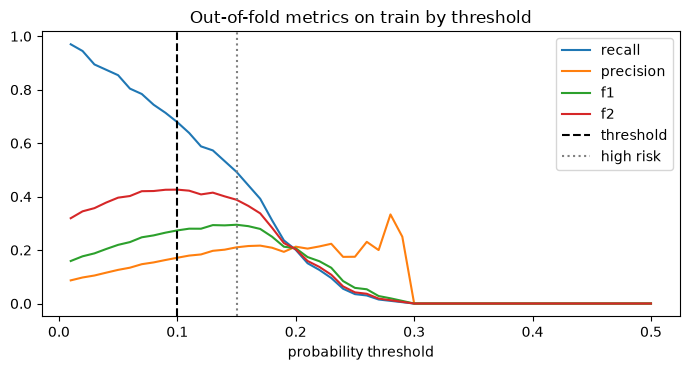

Risk levels on train (out-of-fold):


,patients,strokes,observed_rate,mean_probability,share of patients
level,,,,,
low,3299,64,0.019,0.021,0.807
moderate,322,37,0.115,0.123,0.079
high,466,98,0.210,0.198,0.114


In [15]:
# Decision threshold, chosen on TRAIN only. Every training patient gets a
# probability from a model that did not see that patient (out-of-fold).
from sklearn import metrics

out_of_fold = cross_val_predict(
    final_pipeline, X_train, y_train, cv=cv, method="predict_proba", n_jobs=1
)[:, 1]
print("Out-of-fold ROC-AUC:", round(
    metrics.roc_auc_score(y_train, out_of_fold), 4
))
print(
    "Mean predicted probability:", round(out_of_fold.mean(), 4),
    "| observed stroke rate:", round(y_train.mean(), 4),
)

rows = []
for threshold in np.round(np.arange(0.01, 0.51, 0.01), 2):
    flagged = out_of_fold >= threshold
    rows.append({
        "threshold": threshold,
        "recall": metrics.recall_score(y_train, flagged),
        "precision": metrics.precision_score(
            y_train, flagged, zero_division=0
        ),
        "f1": metrics.f1_score(y_train, flagged),
        # F2 counts recall twice as much as precision.
        "f2": metrics.fbeta_score(y_train, flagged, beta=2),
        "flagged share": flagged.mean(),
    })
curve = pd.DataFrame(rows)

# Screening threshold: best F2 (a missed stroke costs more than a false
# alarm). "High risk" threshold: best F1 (precision and recall balanced).
THRESHOLD = float(curve.loc[curve["f2"].idxmax(), "threshold"])
HIGH_THRESHOLD = float(curve.loc[curve["f1"].idxmax(), "threshold"])
assert HIGH_THRESHOLD > THRESHOLD
print("Decision threshold (best F2):", THRESHOLD)
print("High-risk threshold (best F1):", HIGH_THRESHOLD)

shown = sorted({0.03, 0.05, 0.08, 0.1, 0.15, 0.2, 0.3, 0.5,
                THRESHOLD, HIGH_THRESHOLD})
display(curve[curve["threshold"].isin(shown)].round(3).set_index("threshold"))

fig, ax = plt.subplots(figsize=(7, 3.8))
for column in ["recall", "precision", "f1", "f2"]:
    ax.plot(curve["threshold"], curve[column], label=column)
ax.axvline(THRESHOLD, color="k", linestyle="--", label="threshold")
ax.axvline(HIGH_THRESHOLD, color="gray", linestyle=":", label="high risk")
ax.set_xlabel("probability threshold")
ax.set_title("Out-of-fold metrics on train by threshold")
ax.legend()
plt.tight_layout()
plt.show()


def risk_level(probability):
    return pd.cut(
        probability, [-np.inf, THRESHOLD, HIGH_THRESHOLD, np.inf],
        labels=["low", "moderate", "high"], right=False,
    )


def risk_table(y_true, probability):
    table = pd.DataFrame({
        "level": risk_level(probability),
        "stroke": np.asarray(y_true),
        "probability": probability,
    }).groupby("level", observed=False).agg(
        patients=("stroke", "size"), strokes=("stroke", "sum"),
        observed_rate=("stroke", "mean"),
        mean_probability=("probability", "mean"),
    )
    table["share of patients"] = table["patients"] / table["patients"].sum()
    return table.round(3)


print("Risk levels on train (out-of-fold):")
display(risk_table(y_train, out_of_fold))

**Model choice.** Six candidates were compared with stratified 5-fold cross-validation (CV) on the training set (4087 patients, 4.87 % with a stroke):
- a **baseline** that assigns the prevalence to every patient as the probability (and therefore never predicts a stroke);
- **logistic regression**, linear and interpretable, with and without `class_weight="balanced"`;
- **Random Forest** (Breiman, 2001), with and without balanced class weights;
- **Gradient Boosting** (Friedman, 2001).

| Model | CV ROC-AUC (std) | CV PR-AUC | Recall at 0.5 | Precision at 0.5 | Brier | Mean probability |
|---|---|---|---|---|---|---|
| Random Forest | **0.840** (0.022) | 0.178 | 0.00 | 0.00 | 0.0425 | 0.049 |
| Logistic regression | 0.840 (0.021) | 0.186 | 0.00 | 0.00 | 0.0430 | 0.049 |
| Logistic regression (balanced) | 0.839 (0.020) | 0.192 | 0.82 | 0.14 | 0.1725 | 0.325 |
| Gradient Boosting | 0.838 (0.029) | 0.201 | 0.03 | 0.27 | 0.0436 | 0.048 |
| Random Forest (balanced) | 0.837 (0.022) | 0.175 | 0.75 | 0.14 | 0.1322 | 0.276 |
| Baseline | 0.500 | 0.049 | 0.00 | 0.00 | 0.0463 | 0.049 |

What the table shows:
- **The five models are tied on ROC-AUC.** Their ROC-AUC ranges from 0.837 to 0.840, a difference about five times smaller than the standard deviation across folds (about 0.02). The data does not allow one algorithm to be declared better.
- **PR-AUC orders them differently.** By cross-validated PR-AUC, Gradient Boosting is first (0.201), followed by the weighted logistic regression (0.192), logistic regression (0.186), Random Forest (0.178) and the weighted Random Forest (0.175). The standard deviation of PR-AUC across folds was not computed, so it cannot be said whether these differences exceed the fold noise.
- **Accuracy and the 0.5 threshold are not useful here.** Without class weights, logistic regression and Random Forest never predict a stroke at 0.5 (recall 0) and Gradient Boosting almost never does (recall 0.03), although all three rank patients well.
- **Class weights (He & Garcia, 2009) change the threshold, not the ranking.** With `balanced` weights the recall at 0.5 jumps to 0.75-0.82, but ROC-AUC does not improve, and the probabilities can no longer be read as risk estimates: the weighted logistic regression predicts a mean probability of 0.325 when the real stroke rate is 0.049, and its Brier score (mean squared error of the probability, lower is better) is four times worse (0.17 vs. 0.04). Since JarvisTEC reports a probability to the user, **an unweighted model is preferred and the imbalance is handled by lowering the decision threshold**, which also raises the recall (see the threshold table below).
- **A reference to keep in mind:** age alone, used as a score with no model at all, already gives a ROC-AUC of 0.834 on the training set.

**Selection metric, stated openly.** The model is selected by cross-validated **ROC-AUC** (`scoring = "roc_auc"` in the code), a rule fixed in advance. ROC-AUC was used because it does not depend on a decision threshold, and the threshold is chosen afterwards in a separate step. By that rule the unweighted **Random Forest** is chosen (0.8404), but its lead over logistic regression (0.8398) and Gradient Boosting (0.8382) is far inside the fold noise (standard deviation 0.02-0.03): on ROC-AUC the candidates are tied and the pick among them is close to arbitrary. Section 1 says that PR-AUC is the more informative metric for a rare positive class, and **selecting by PR-AUC would have pointed to a different model, Gradient Boosting** (0.201 against 0.178 for Random Forest). This is a weakness of the selection, not something hidden: the rule was not changed after seeing the table, so that the metric was not picked to suit a result. Gradient Boosting was neither tuned nor scored on the test set, so whether it would have done better there is unknown. Logistic regression would be an equally defensible (and simpler) choice.

**Hyperparameter tuning.** **Only the selected model (Random Forest) was tuned.** The other candidates were compared with the fixed hyperparameters shown in the code, so the table above compares untuned models. `RandomizedSearchCV` evaluated 20 combinations with the same cross-validation, on the training set only, scored by ROC-AUC:
- **Searched hyperparameters:** number of trees (200, 400), maximum depth (none, 5, 10), minimum samples per leaf (5, 10, 20, 40) and fraction of features per split (`sqrt`, 0.5).
- **Best combination:** 400 trees, `max_depth=10`, `min_samples_leaf=20` and `max_features=0.5`. Large leaves make each tree average over at least 20 patients, which smooths the probability of a rare event.
- **Result:** the cross-validated ROC-AUC went from 0.8404 to 0.8467, so it was adopted. The gain is small (0.006, less than the standard deviation across folds of 0.021), and the 20 combinations ranged only from 0.834 to 0.847: the model is not very sensitive to these hyperparameters.

**Decision threshold (train only).** Every training patient received an out-of-fold probability, that is, one produced by a model trained without that patient (out-of-fold ROC-AUC 0.847; mean predicted probability 0.0489 against an observed rate of 0.0487, so the probabilities are well calibrated on average). Precision, recall, F1 and F2 were then computed for thresholds from 0.01 to 0.50:

| Threshold | Recall | Precision | F1 | F2 | Patients flagged |
|---|---|---|---|---|---|
| 0.05 | 0.854 | 0.126 | 0.219 | 0.396 | 33.0 % |
| 0.08 | 0.744 | 0.154 | 0.255 | 0.421 | 23.5 % |
| **0.10** | 0.678 | 0.171 | 0.274 | **0.426** | 19.3 % |
| **0.15** | 0.492 | 0.210 | **0.295** | 0.388 | 11.4 % |
| 0.20 | 0.201 | 0.213 | 0.207 | 0.203 | 4.6 % |
| 0.50 | 0 | 0 | 0 | 0 | 0 % |

- **Decision threshold = 0.10**, the one with the best **F2** (a score that weights recall twice as much as precision, because missing a patient at risk is assumed to be the more costly error). A patient is flagged when the estimated probability is at least 10 %, about twice the average risk.
- **High-risk threshold = 0.15**, the one with the best **F1**.
- F2 is almost the same at 0.08 and 0.10 (0.421 vs. 0.426), so the exact value is not sharply determined; 0.10 is the result of the rule fixed in advance.
- **Risk levels:** *low* below 0.10, *moderate* from 0.10 to 0.15, *high* from 0.15. On the training set (out-of-fold) the observed stroke rate was 1.9 % in the low level (80.7 % of the patients), 11.5 % in the moderate level (7.9 %) and 21.0 % in the high level (11.4 %).

The test set was not used for any of these decisions.

## 5. Evaluation

The chosen model is evaluated on the held-out test set, which was not used for training, model selection or tuning. Any other model or rule scored on the test set below is shown for reference only and did not influence a choice.

              precision    recall  f1-score   support

   no stroke      0.982     0.840     0.905       972
      stroke      0.183     0.700     0.290        50

    accuracy                          0.833      1022
   macro avg      0.583     0.770     0.598      1022
weighted avg      0.943     0.833     0.875      1022

Confusion matrix [[TN, FP], [FN, TP]]:
[[816 156]
 [ 15  35]]


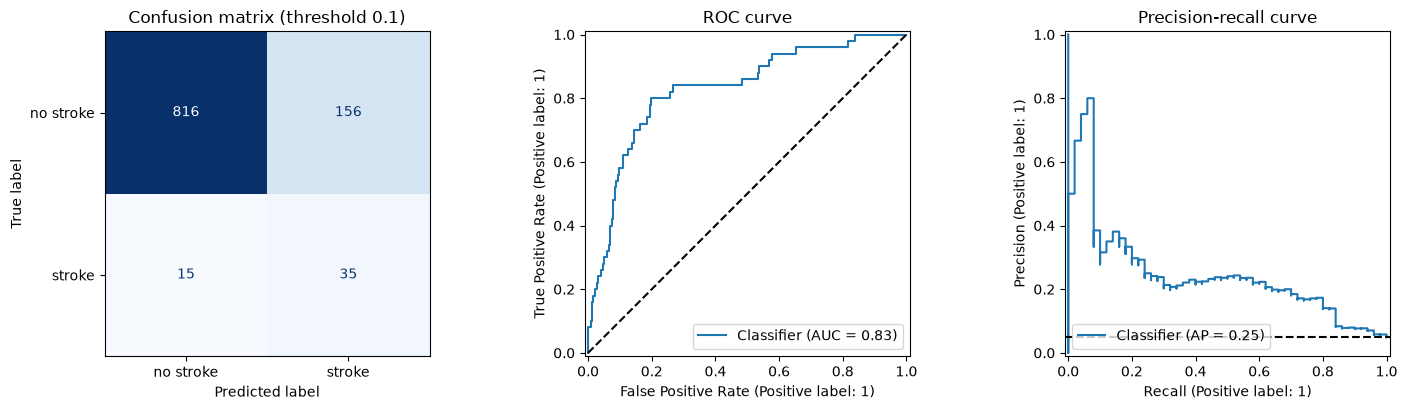

roc_auc        0.8279
pr_auc         0.2466
recall         0.7000
precision      0.1832
f1             0.2905
specificity    0.8395
accuracy       0.8327
brier          0.0417
Name: test metrics, dtype: float64

,model,baseline (never predicts stroke),flag everyone
roc_auc,0.8279,0.5000,NaN
pr_auc,0.2466,0.0489,NaN
recall,0.7000,0.0000,1.0000
precision,0.1832,0.0000,0.0489
f1,0.2905,0.0000,0.0933
specificity,0.8395,1.0000,0.0000
accuracy,0.8327,0.9511,0.0489
brier,0.0417,0.0465,NaN


Stroke patients in test: 50 of 1022
Patients flagged by the model: 191


In [16]:
probabilities = final_pipeline.predict_proba(X_test)[:, 1]
predictions = (probabilities >= THRESHOLD).astype(int)


def threshold_metrics(y_true, flagged):
    tn, fp, fn, tp = metrics.confusion_matrix(y_true, flagged).ravel()
    return {
        "recall": metrics.recall_score(y_true, flagged),
        "precision": metrics.precision_score(y_true, flagged, zero_division=0),
        "f1": metrics.f1_score(y_true, flagged),
        "specificity": tn / (tn + fp),
        "accuracy": metrics.accuracy_score(y_true, flagged),
    }


test_metrics = {
    "roc_auc": metrics.roc_auc_score(y_test, probabilities),
    "pr_auc": metrics.average_precision_score(y_test, probabilities),
    **threshold_metrics(y_test, predictions),
    "brier": metrics.brier_score_loss(y_test, probabilities),
}
print(metrics.classification_report(
    y_test, predictions, target_names=["no stroke", "stroke"], digits=3
))
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(metrics.confusion_matrix(y_test, predictions))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
metrics.ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, display_labels=["no stroke", "stroke"],
    ax=axes[0], cmap="Blues", colorbar=False,
)
axes[0].set_title(f"Confusion matrix (threshold {THRESHOLD})")
metrics.RocCurveDisplay.from_predictions(y_test, probabilities, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_title("ROC curve")
metrics.PrecisionRecallDisplay.from_predictions(
    y_test, probabilities, ax=axes[2]
)
axes[2].axhline(y_test.mean(), color="k", linestyle="--")
axes[2].set_title("Precision-recall curve")
plt.tight_layout()
plt.show()

test_metrics = {k: round(float(v), 4) for k, v in test_metrics.items()}
display(pd.Series(test_metrics, name="test metrics"))

# Baselines on the same test set, to check the model really adds value.
baseline = Pipeline([
    ("prep", preprocessor),
    ("model", candidates["Baseline"]),
]).fit(X_train, y_train)
baseline_probabilities = baseline.predict_proba(X_test)[:, 1]
baseline_metrics = {
    "roc_auc": metrics.roc_auc_score(y_test, baseline_probabilities),
    "pr_auc": metrics.average_precision_score(y_test, baseline_probabilities),
    **threshold_metrics(y_test, baseline.predict(X_test)),
    "brier": metrics.brier_score_loss(y_test, baseline_probabilities),
}
baseline_metrics = {k: round(float(v), 4) for k, v in baseline_metrics.items()}
flag_everyone = {
    k: round(float(v), 4)
    for k, v in threshold_metrics(y_test, np.ones(len(y_test), int)).items()
}
display(pd.DataFrame({
    "model": test_metrics,
    "baseline (never predicts stroke)": baseline_metrics,
    "flag everyone": flag_everyone,
}))
print("Stroke patients in test:", int(y_test.sum()), "of", len(y_test))
print("Patients flagged by the model:", int(predictions.sum()))

In [17]:
# The same model at other thresholds, and the untuned candidate, on the same
# test set. For reference only: nothing here was used to choose the model.
rows = {}
for label, threshold in {
    f"chosen ({THRESHOLD})": THRESHOLD,
    f"high risk ({HIGH_THRESHOLD})": HIGH_THRESHOLD,
    "default (0.5)": 0.5,
}.items():
    flagged = (probabilities >= threshold).astype(int)
    rows[label] = {
        **threshold_metrics(y_test, flagged), "flagged": int(flagged.sum()),
    }
display(pd.DataFrame(rows).T.round(4))

untuned_model = Pipeline([
    ("prep", preprocessor), ("model", candidates[BEST]),
]).fit(X_train, y_train)
untuned_probabilities = untuned_model.predict_proba(X_test)[:, 1]
print(
    "Untuned", BEST, "on test: ROC-AUC",
    round(metrics.roc_auc_score(y_test, untuned_probabilities), 4),
    "| PR-AUC",
    round(metrics.average_precision_score(y_test, untuned_probabilities), 4),
)

print(
    "Age alone as a score on test: ROC-AUC",
    round(metrics.roc_auc_score(y_test, X_test["age"]), 4),
    "| PR-AUC",
    round(metrics.average_precision_score(y_test, X_test["age"]), 4),
)

print("Risk levels on test:")
display(risk_table(y_test, probabilities))

,recall,precision,f1,specificity,accuracy,flagged
chosen (0.1),0.70,0.1832,0.2905,0.8395,0.8327,191.0
high risk (0.15),0.52,0.2364,0.3250,0.9136,0.8943,110.0
default (0.5),0.00,0.0000,0.0000,1.0000,0.9511,0.0


Untuned Random Forest on test: ROC-AUC 0.8262 | PR-AUC 0.2443
Age alone as a score on test: ROC-AUC 0.8347 | PR-AUC 0.2087
Risk levels on test:


,patients,strokes,observed_rate,mean_probability,share of patients
level,,,,,
low,831,15,0.018,0.020,0.813
moderate,81,9,0.111,0.126,0.079
high,110,26,0.236,0.205,0.108


num__age                               0.4267
num__avg_glucose_level                 0.2063
num__bmi                               0.1669
num__hypertension                      0.0395
num__heart_disease                     0.0238
cat__smoking_status_never smoked       0.0190
cat__work_type_Private                 0.0182
cat__gender_Male                       0.0125
cat__gender_Female                     0.0117
cat__work_type_Self-employed           0.0114
cat__residence_type_Urban              0.0113
cat__smoking_status_formerly smoked    0.0101
cat__residence_type_Rural              0.0099
cat__ever_married_No                   0.0097
cat__ever_married_Yes                  0.0090
cat__smoking_status_smokes             0.0068
cat__smoking_status_Unknown            0.0048
cat__work_type_Govt_job                0.0021
cat__work_type_children                0.0002
cat__work_type_Never_worked            0.0000
Name: Feature importance, dtype: float64

,roc_auc drop (mean),std
age,0.2291,0.0213
avg_glucose_level,0.0149,0.0062
bmi,0.0086,0.0060
smoking_status,0.0075,0.0039
work_type,0.0051,0.0019
heart_disease,0.0049,0.0025
ever_married,0.0006,0.0044
gender,-0.0008,0.0016
hypertension,-0.0011,0.0044
residence_type,-0.0023,0.0011


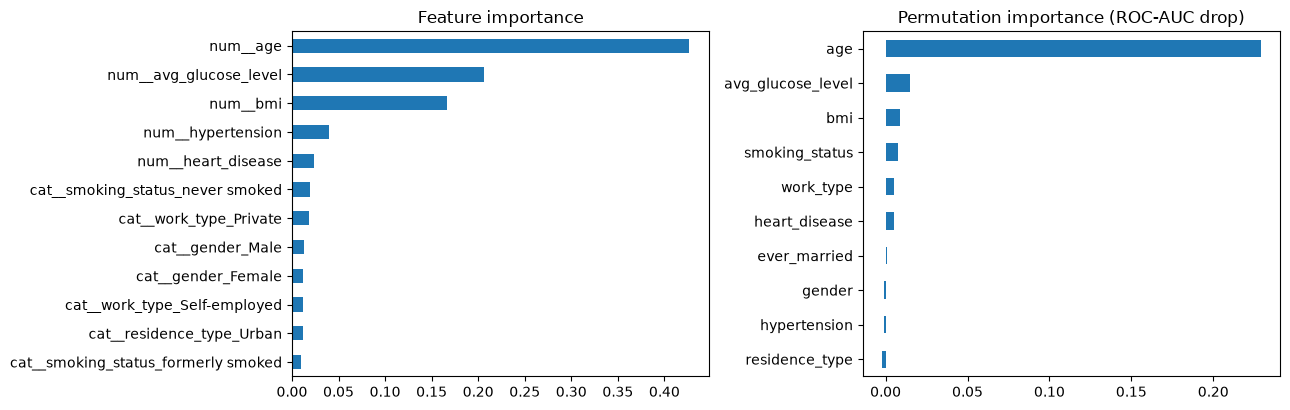

In [18]:
# Feature importance. For a linear model: coefficients as odds ratios
# (numeric inputs are standardized, so the ratio is per standard deviation).
estimator = final_pipeline.named_steps["model"]
feature_names = final_pipeline.named_steps["prep"].get_feature_names_out()
if hasattr(estimator, "feature_importances_"):
    weights = pd.Series(estimator.feature_importances_, index=feature_names)
    title = "Feature importance"
    display(weights.sort_values(ascending=False).round(4).rename(title))
else:
    weights = pd.Series(estimator.coef_[0], index=feature_names)
    title = "Coefficients (log-odds, scaled inputs)"
    display(pd.DataFrame({
        "coefficient": weights, "odds ratio": np.exp(weights),
    }).sort_values("coefficient", key=abs, ascending=False).round(3))
    scaler = final_pipeline.named_steps["prep"].named_transformers_["num"]
    print("Standard deviation of the numeric inputs (train):")
    print(dict(zip(numeric_features, scaler["scale"].scale_.round(2))))

# Permutation importance on the original columns: how much ROC-AUC is lost
# when one input is shuffled (test set, descriptive only).
from sklearn.inspection import permutation_importance

permutation = permutation_importance(
    final_pipeline, X_test, y_test, scoring="roc_auc", n_repeats=30,
    random_state=SEED, n_jobs=1,
)
permutation = pd.DataFrame({
    "roc_auc drop (mean)": permutation.importances_mean,
    "std": permutation.importances_std,
}, index=X_test.columns).sort_values("roc_auc drop (mean)", ascending=False)
display(permutation.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
weights.sort_values(key=abs).tail(12).plot(kind="barh", ax=axes[0], title=title)
permutation["roc_auc drop (mean)"].sort_values().plot(
    kind="barh", ax=axes[1], title="Permutation importance (ROC-AUC drop)"
)
plt.tight_layout()
plt.show()

In [19]:
# Error analysis on the test set: who is missed and who is flagged in vain?
errors = X_test.assign(
    stroke=y_test, probability=probabilities, flagged=predictions
)
errors["age_band"] = pd.cut(
    errors["age"], AGE_BINS, labels=AGE_LABELS, right=False
)
by_band = errors.groupby("age_band", observed=False).agg(
    patients=("stroke", "size"),
    strokes=("stroke", "sum"),
    flagged=("flagged", "sum"),
    detected=("stroke", lambda s: int((s & errors.loc[s.index, "flagged"]).sum())),
)
by_band["recall"] = (by_band["detected"] / by_band["strokes"]).round(3)
by_band["precision"] = (by_band["detected"] / by_band["flagged"]).round(3)
display(by_band)

missed = errors[(errors["stroke"] == 1) & (errors["flagged"] == 0)]
print("Missed strokes (false negatives):", len(missed))
display(
    missed.drop(columns=["stroke", "flagged", "age_band"])
    .sort_values("probability").round(3)
)
false_alarms = errors[(errors["stroke"] == 0) & (errors["flagged"] == 1)]
true_negatives = errors[(errors["stroke"] == 0) & (errors["flagged"] == 0)]
detected = errors[(errors["stroke"] == 1) & (errors["flagged"] == 1)]
display(pd.DataFrame({
    "detected strokes": detected[["age", "avg_glucose_level", "bmi"]].median(),
    "missed strokes": missed[["age", "avg_glucose_level", "bmi"]].median(),
    "false alarms": false_alarms[["age", "avg_glucose_level", "bmi"]].median(),
    "correctly not flagged": true_negatives[
        ["age", "avg_glucose_level", "bmi"]
    ].median(),
}).round(1).rename_axis("median values"))
print(
    "False alarms:", len(false_alarms),
    "| share aged 60 or more:",
    round((false_alarms["age"] >= 60).mean(), 3),
)
print(
    "Patients aged 60+ in test:", int((errors["age"] >= 60).sum()),
    "| flagged:", int(errors.loc[errors["age"] >= 60, "flagged"].sum()),
)
print(
    "Highest probability in test:", round(probabilities.max(), 3),
    "| patients above 0.5:", int((probabilities >= 0.5).sum()),
)

# Subgroup with a missing BMI (imputed with the training median).
no_bmi = errors[errors["bmi"].isna()]
print(
    "Test patients without bmi:", len(no_bmi),
    "| strokes:", int(no_bmi["stroke"].sum()),
    "| detected:", int((no_bmi["stroke"] & no_bmi["flagged"]).sum()),
)

,patients,strokes,flagged,detected,recall,precision
age_band,,,,,,
< 40,434,5,0,0,0.000,NaN
40-49,149,3,0,0,0.000,NaN
50-59,164,4,25,1,0.250,0.040
60-69,130,6,45,5,0.833,0.111
70+,145,32,121,29,0.906,0.240


Missed strokes (false negatives): 15


,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,probability
31,Male,42.0,0,0,Yes,Private,Rural,83.41,25.4,Unknown,0.001
210,Female,39.0,0,0,Yes,Private,Urban,83.24,26.3,never smoked,0.001
182,Female,32.0,0,0,Yes,Private,Rural,76.13,29.9,smokes,0.003
228,Female,39.0,0,0,Yes,Self-employed,Urban,97.76,29.6,smokes,0.006
245,Female,14.0,0,0,No,children,Rural,57.93,30.9,Unknown,0.007
133,Female,38.0,0,0,Yes,Private,Rural,101.45,NaN,formerly smoked,0.009
88,Male,47.0,0,0,Yes,Private,Urban,86.94,41.1,formerly smoked,0.009
94,Male,45.0,0,0,Yes,Private,Rural,64.14,29.4,never smoked,0.013
194,Female,72.0,0,0,Yes,Private,Rural,97.92,26.9,smokes,0.057
80,Male,59.0,0,0,Yes,Private,Rural,96.16,44.1,Unknown,0.060


,detected strokes,missed strokes,false alarms,correctly not flagged
median values,,,,
age,78.0,47.0,74.0,37.5
avg_glucose_level,133.2,92.6,133.9,89.4
bmi,27.9,29.5,28.8,27.6


False alarms: 156 | share aged 60 or more: 0.846
Patients aged 60+ in test: 275 | flagged: 166
Highest probability in test: 0.347 | patients above 0.5: 0
Test patients without bmi: 38 | strokes: 3 | detected: 2


**Interpretation.** On the test set (1022 unseen patients, 50 with a stroke) the model reaches **ROC-AUC 0.828** and **PR-AUC 0.247** (baseline: 0.500 and 0.049). At the threshold of 0.10 chosen on the training set:

| | Predicted no stroke | Predicted stroke |
|---|---|---|
| **No stroke (972)** | 816 | 156 |
| **Stroke (50)** | 15 | 35 |

- **Recall 0.70:** it finds 35 of the 50 patients with a stroke and misses 15.
- **Precision 0.18:** it flags 191 patients and 156 of them are false alarms; fewer than one in five flagged patients had a stroke. F1 of the stroke class: 0.29.
- **Specificity 0.84** and accuracy 0.83. The accuracy is *lower* than the 0.951 of the baseline that never predicts a stroke, which is why accuracy was not used as the metric: that baseline identifies no patient. Both figures are also inflated by the young patients kept in the data (section 2): the 434 test patients under 40 are never flagged, and only 5 of them had a stroke, so that group alone supplies a large share of the correct rejections.
- **These are modest results.** The test ROC-AUC (0.828) is slightly below the cross-validated one (0.847), a gap within the standard deviation across folds (0.021). With only 50 positive patients in the test set, every figure above is uncertain: one patient more or less changes the recall by 2 percentage points.
- **The model does not beat age alone at ranking.** Using age as the score gives a ROC-AUC of **0.835** on the same test set (PR-AUC 0.209), slightly *above* the model's 0.828. The model's advantage is limited to the PR-AUC (0.247 vs. 0.209) and to producing a probability instead of only a ranking.
- **The probabilities are usable as estimates:** the Brier score is 0.0417 (baseline 0.0465), and the observed stroke rate in each risk level on the test set (1.8 % low, 11.1 % moderate, 23.6 % high) is close to the mean predicted probability (2.0 %, 12.6 %, 20.5 %) and to what was seen on train. The highest probability the model gives to any test patient is 0.35: it never states that a stroke is likely, only that the risk is several times the average.

**Other thresholds (same model, reference only).** At the high-risk threshold of 0.15 the model flags 110 patients, with recall 0.52 and precision 0.24. At the default threshold of 0.5 it flags nobody.

**Error analysis:**
- **By age:** the model flags **nobody under 50**, so the 8 test patients under 50 who had a stroke are all missed. It finds 1 of the 4 strokes between 50 and 59, 5 of 6 between 60 and 69 and 29 of 32 from 70 on. In practice it behaves much like an age rule, with small adjustments from the other inputs.
- **Missed strokes (15):** their median age is 47 (78 for the detected ones) and their median glucose 92.6 (133.2 for the detected ones). 14 of the 15 had neither hypertension nor heart disease, and 8 received a probability below 2 %. The model finds little in the ten inputs that separates these patients from people of the same age without a stroke; finding them would probably require other data.
- **False alarms (156):** 85 % are aged 60 or more, with a median age of 74 and a median glucose of 133.9, a profile similar to that of the detected strokes. The model flags 166 of the 275 test patients aged 60 or more.
- **Missing BMI:** 38 test patients have no BMI (imputed with the median); 3 had a stroke and 2 were detected. The group is too small to conclude anything.

**Effect of tuning.** The Random Forest before tuning reached a test ROC-AUC of 0.826 and a PR-AUC of 0.244, against 0.828 and 0.247 after tuning: no real difference, as the cross-validation results suggested.

**Feature importance.** In the forest's impurity importance, **age** holds 0.43, average glucose 0.21 and BMI 0.17; hypertension (0.04), heart disease (0.02) and every category are far behind. Impurity importance tends to favor continuous variables, so permutation importance was also computed on the test set: shuffling **age** lowers the test ROC-AUC by **0.229**, while glucose costs 0.015, BMI 0.009 and every other input less than 0.01. Shuffling hypertension, gender, residence or marital status produces no measurable change. Hypertension and heart disease are associated with stroke in the exploration (section 3), but they are rare (9.7 % and 5.4 % of the patients) and add little once age is known.

**Possible causes of error:** there are very few positive cases (249 in total); the main clinical predictors of stroke are present only as yes/no flags or are missing (blood pressure values, diabetes, atrial fibrillation, cholesterol, family history, previous strokes); `smoking_status` is unknown for 30 % of the patients; and the dataset does not record when the stroke happened relative to the measurements.

## Export for the backend

In [20]:
joblib.dump(final_pipeline, ARTIFACTS / f"{MODEL_NAME}.joblib")

# Typical input: becomes the `default_input` of the backend adapter.
example = X_train.median(numeric_only=True).round(1).to_dict()
for column in ["hypertension", "heart_disease"]:
    example[column] = int(example[column])
for column in categorical_features:
    example[column] = X_train[column].mode().iloc[0]
example_frame = pd.DataFrame([example])[X.columns]
example_probability = float(final_pipeline.predict_proba(example_frame)[0, 1])

meta = {
    "model": BEST,
    "hyperparameters": HYPERPARAMETERS,
    "task": TASK_TYPE,
    "features": X.columns.tolist(),
    "test_metrics": test_metrics,
    "baseline_test_metrics": baseline_metrics,
    # Probability from which a patient is flagged (chosen on train, CV).
    "threshold": THRESHOLD,
    # Lower bound of each risk level; below "moderate" the risk is "low".
    "risk_thresholds": {"moderate": THRESHOLD, "high": HIGH_THRESHOLD},
    "default_input": example,
    "sklearn_version": sklearn.__version__,
    "classes": sorted(int(c) for c in y.unique()),
    "positive_class": 1,
    "n_train": len(X_train),
    "n_test": len(X_test),
}
meta_path = ARTIFACTS / f"{MODEL_NAME}.meta.json"
meta_path.write_text(json.dumps(meta, indent=2, default=str))

size_kb = (ARTIFACTS / f"{MODEL_NAME}.joblib").stat().st_size / 1024
print(f"Saved artifacts/{MODEL_NAME}.joblib ({size_kb:.0f} KB) "
      f"and {meta_path.name}")
print("\nCopy to backend/models/<package>/ (schema.py / default_input):")
print(json.dumps(example, indent=2, default=str))
print("Probability for this typical input:", round(example_probability, 4),
      "->", risk_level(np.array([example_probability]))[0])

Saved artifacts/stroke.joblib (3028 KB) and stroke.meta.json

Copy to backend/models/<package>/ (schema.py / default_input):
{
  "age": 45.0,
  "hypertension": 0,
  "heart_disease": 0,
  "avg_glucose_level": 91.9,
  "bmi": 28.1,
  "gender": "Female",
  "ever_married": "Yes",
  "work_type": "Private",
  "residence_type": "Urban",
  "smoking_status": "never smoked"
}
Probability for this typical input: 0.0135 -> low


## 6. Conclusion

A Random Forest estimates the probability of stroke with a **test ROC-AUC of 0.83 and PR-AUC of 0.25** (baseline 0.50 and 0.05). With the decision threshold of 0.10 chosen by cross-validation on the training set, it finds **70 % of the patients with a stroke (35 of 50)** at the cost of a **precision of 18 %** (156 false alarms). The risk levels it reports are consistent with what is observed (about 2 % of strokes in the low level, 11 % in the moderate and 24 % in the high). It is a **modest model**: it is essentially driven by age, it does not rank patients better than age alone, and in the test set it misses every stroke in patients under 50. It can serve as a demonstration of a **screening estimate** that advises an older person with high glucose to get a check-up; it must not be used to reassure anyone, and it is **not a diagnosis**.

**Limitations:**
- Only 249 patients with a stroke (50 in the test set), so every metric has a wide margin of uncertainty.
- The origin of the data is not documented (hospital, country, period, how patients were selected), so the population to which the model applies is unknown.
- The data is cross-sectional: the model estimates how similar a person is to patients who had a stroke, not the probability of having one within a given period.
- Key clinical predictors are absent, and the missing BMI values and the `Unknown` smoking category suggest data-collection artifacts.
- A low risk level means "low according to ten variables", with an observed stroke rate of about 2 % in that level: young patients with a stroke are invisible to the model.
- Precision is low: most flagged patients did not have a stroke.
- The data includes children and teenagers (856 patients under 18), who almost never have a stroke; they make accuracy and specificity look better than they would on an adult population.
- The model was selected by ROC-AUC, on which the candidates are tied within fold noise; by cross-validated PR-AUC, the metric better suited to a rare class, Gradient Boosting ranked first and was not the model chosen.

**Future improvements:**
- Train on a documented clinical cohort with follow-up time and proper predictors (blood pressure, diabetes, atrial fibrillation), as the Framingham profile does.
- Report an interval for the probability, not only a point estimate.
- Calibrate and validate the probabilities on an external dataset.
- Choose the threshold from an explicit cost of a missed case against a false alarm, agreed with a health professional.
- Compare with the simpler logistic regression on the deployment criteria (interpretability, size), since both perform the same in cross-validation.

**Voice commands for this model:** *"JarvisTEC, stroke risk"*, *"JarvisTEC, risk of a stroke"*, *"JarvisTEC, risk of stroke"*, *"JarvisTEC, stroke"*

### References

- Feigin, V. L., et al. (2021). Global, regional, and national burden of stroke and its risk factors, 1990-2019: A systematic analysis for the Global Burden of Disease Study 2019. *The Lancet Neurology, 20*(10), 795-820. https://doi.org/10.1016/S1474-4422(21)00252-0
- O'Donnell, M. J., et al. (2016). Global and regional effects of potentially modifiable risk factors associated with acute stroke in 32 countries (INTERSTROKE): A case-control study. *The Lancet, 388*(10046), 761-775. https://doi.org/10.1016/S0140-6736(16)30506-2
- Wolf, P. A., D'Agostino, R. B., Belanger, A. J., & Kannel, W. B. (1991). Probability of stroke: A risk profile from the Framingham Study. *Stroke, 22*(3), 312-318. https://doi.org/10.1161/01.STR.22.3.312
- Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLoS ONE, 10*(3), e0118432. https://doi.org/10.1371/journal.pone.0118432
- He, H., & Garcia, E. A. (2009). Learning from imbalanced data. *IEEE Transactions on Knowledge and Data Engineering, 21*(9), 1263-1284. https://doi.org/10.1109/TKDE.2008.239
- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5-32. https://doi.org/10.1023/A:1010933404324
- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189-1232. https://doi.org/10.1214/aos/1013203451
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.
- fedesoriano. (2021). *Stroke Prediction Dataset* [Data set]. Kaggle. https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset